In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

# Configuración de entorno y reproducibilidad
SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

# Búsqueda robusta de la raíz del proyecto y carga del parquet limpio
RAIZ = next(
    p
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "proyecto_equipo" / "datos").is_dir() or (p / "datos").is_dir()
)
RUTA_PARQUET = next(RAIZ.glob("**/ai_company_adoption_limpio.parquet"))
df = pd.read_parquet(RUTA_PARQUET)

print(
    f"Dataset cargado: {len(df):,} filas | {df['company_id'].nunique():,} empresas"
)

Dataset cargado: 150,000 filas | 10,000 empresas


In [2]:
# Definición de la variable objetivo
objetivo = "ai_adoption_rate"

# Selección de predictores estructurales
columnas_categoricas = ["country", "industry"]
columnas_log = ["num_employees", "annual_revenue_usd_millions"]
columnas_escaladas = ["company_age", "survey_year"]
predictores = columnas_log + columnas_escaladas + columnas_categoricas

# Variables de exclusión estricta para prevenir Data Leakage:
# - 'ai_adoption_stage': es la discretización directa del objetivo.
# - 'company_id': identificador que se reserva para armar los grupos.
# - 'region' y 'company_size': redundantes con country y num_employees.
# - Métricas contemporáneas/futuras de impacto de IA (productividad, ahorro, etc.).

X = df[predictores].copy()
y = pd.to_numeric(df[objetivo], errors="raise").astype(float)
grupos = df["company_id"].astype("string")

# Partición Hold-out agrupada (80% Train / 20% Test en empresas completas)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
train_idx, test_idx = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train = grupos.iloc[train_idx]

print(
    f"Entrenamiento: {len(X_train):,} filas ({grupos_train.nunique():,} empresas)"
)
print(
    f"Prueba:        {len(X_test):,} filas"
    f" ({grupos.iloc[test_idx].nunique():,} empresas)"
)

Entrenamiento: 119,969 filas (8,000 empresas)
Prueba:        30,031 filas (2,000 empresas)


In [3]:
# Transformador numérico con compresión logarítmica para variables asimétricas
preparador_log = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("escalar", StandardScaler()),
])

# Transformador para variables continuas lineales/temporales
preparador_escalado = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
])

# Transformador para variables categóricas
preparador_categorico = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", sparse_output=False)),
])

preprocesador = ColumnTransformer(
    transformers=[
        ("num_log", preparador_log, columnas_log),
        ("num_std", preparador_escalado, columnas_escaladas),
        ("cat", preparador_categorico, columnas_categoricas),
    ],
    remainder="drop",
)

In [5]:
# Validación cruzada agrupada de 5 pliegues
cv_agrupado = GroupKFold(n_splits=5)

# 1. Baseline: DummyRegressor (media de train)
pipe_dummy = Pipeline([("dummy", DummyRegressor(strategy="mean"))])
pipe_dummy.fit(X_train, y_train)

# 2. Modelo Lineal Regularizado: Ridge con búsqueda de alpha óptimo
pipe_ridge = Pipeline([
    ("prepro", preprocesador),
    ("modelo", Ridge(random_state=SEMILLA)),
])

# Cambiar n_jobs=-1 por n_jobs=1 o n_jobs=2 para evitar saturar la memoria virtual en Windows
grid_ridge = GridSearchCV(
    pipe_ridge,
    param_grid={"modelo__alpha": [1.0, 10.0, 50.0, 100.0, 200.0]},
    cv=cv_agrupado,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,  # <--- Evita el BrokenProcessPool / ImportError de cython_blas
)
grid_ridge.fit(X_train, y_train, groups=grupos_train)
mejor_ridge = grid_ridge.best_estimator_
print(f"Mejor alpha para Ridge: {grid_ridge.best_params_['modelo__alpha']}")

# 3. Modelo No Lineal: Árbol de Decisión con poda
pipe_tree = Pipeline([
    ("prepro", preprocesador),
    (
        "modelo",
        DecisionTreeRegressor(
            max_depth=6, min_samples_leaf=50, random_state=SEMILLA
        ),
    ),
])
pipe_tree.fit(X_train, y_train)

# 4. Modelo de Ensamble: Random Forest Regressor
# En Random Forest también conviene usar n_jobs=2 si tu máquina tiene poca memoria
pipe_rf = Pipeline([
    ("prepro", preprocesador),
    (
        "modelo",
        RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            min_samples_leaf=20,
            random_state=SEMILLA,
            n_jobs=2,  # <--- n_jobs moderado
        ),
    ),
])
pipe_rf.fit(X_train, y_train)
print("Entrenamiento de todos los modelos finalizado exitosamente.")

Mejor alpha para Ridge: 100.0
Entrenamiento de todos los modelos finalizado exitosamente.


In [6]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
  y_pred_tr = modelo.predict(X_tr)
  y_pred_te = modelo.predict(X_te)

  mae_tr, mae_te = mean_absolute_error(
      y_tr, y_pred_tr
  ), mean_absolute_error(y_te, y_pred_te)
  rmse_tr = np.sqrt(mean_squared_error(y_tr, y_pred_tr))
  rmse_te = np.sqrt(mean_squared_error(y_te, y_pred_te))
  r2_tr, r2_te = r2_score(y_tr, y_pred_tr), r2_score(y_te, y_pred_te)

  return {
      "Modelo": nombre,
      "MAE (Train)": round(mae_tr, 3),
      "MAE (Test)": round(mae_te, 3),
      "RMSE (Train)": round(rmse_tr, 3),
      "RMSE (Test)": round(rmse_te, 3),
      "R² (Train)": round(r2_tr, 3),
      "R² (Test)": round(r2_te, 3),
      "Δ RMSE (Overfit)": round(rmse_te - rmse_tr, 3),
  }


modelos = [
    ("Baseline (Dummy Media)", pipe_dummy),
    ("Regresión Ridge (Optimizada)", mejor_ridge),
    ("Árbol de Decisión (max_depth=6)", pipe_tree),
    ("Random Forest (100 árboles)", pipe_rf),
]

resultados = [
    evaluar_modelo(nom, mod, X_train, y_train, X_test, y_test)
    for nom, mod in modelos
]
df_comparativa = pd.DataFrame(resultados)

# Visualizar tabla comparativa
display(df_comparativa)

# Guardar tabla en CSV para anexar al informe
df_comparativa.to_csv("tabla_comparativa_modelos_tp2.csv", index=False)

,Modelo,MAE (Train),MAE (Test),RMSE (Train),RMSE (Test),R² (Train),R² (Test),Δ RMSE (Overfit)
0,Baseline (Dummy Media),11.638,11.716,14.524,14.624,0.000,-0.000,0.100
1,Regresión Ridge (Optimizada),11.024,11.134,13.751,13.888,0.104,0.098,0.137
2,Árbol de Decisión (max_depth=6),10.993,11.074,13.714,13.836,0.108,0.105,0.122
3,Random Forest (100 árboles),10.691,11.067,13.342,13.815,0.156,0.107,0.473


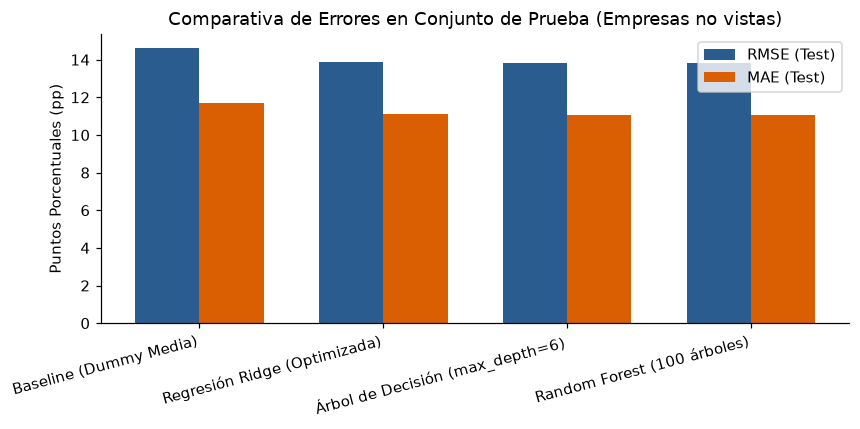

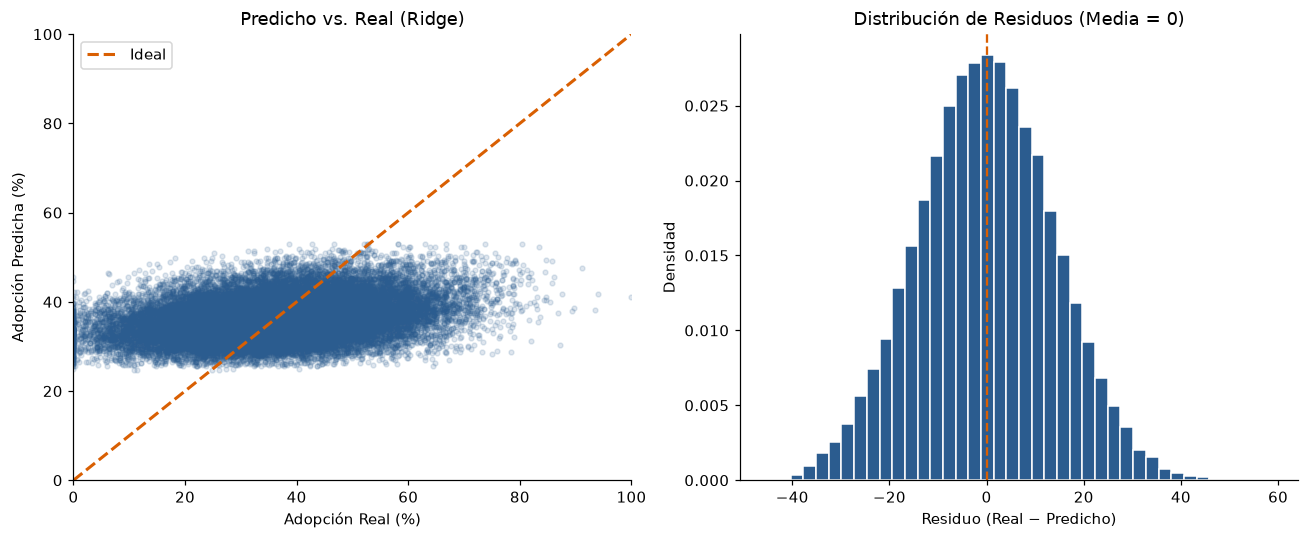

Gráficos exportados con éxito en salidas_graficas/


In [7]:
# Crear carpeta de salidas para las imágenes del informe
os.makedirs("salidas_graficas", exist_ok=True)

# 1. Gráfico de Barras: Comparación de RMSE y MAE (Test)
fig, ax = plt.subplots(figsize=(8, 4))
x_loc = np.arange(len(df_comparativa))
ancho = 0.35

ax.bar(
    x_loc - ancho / 2,
    df_comparativa["RMSE (Test)"],
    ancho,
    label="RMSE (Test)",
    color="#2b5c8f",
)
ax.bar(
    x_loc + ancho / 2,
    df_comparativa["MAE (Test)"],
    ancho,
    label="MAE (Test)",
    color="#d95f02",
)
ax.set_ylabel("Puntos Porcentuales (pp)")
ax.set_title("Comparativa de Errores en Conjunto de Prueba (Empresas no vistas)")
ax.set_xticks(x_loc)
ax.set_xticklabels(df_comparativa["Modelo"], rotation=15, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(
    "salidas_graficas/comparativa_errores_test.png", dpi=300, bbox_inches="tight"
)
plt.show()

# 2. Gráfico Predicho vs Real y Diagnóstico de Residuos (del mejor modelo Ridge)
y_test_pred = mejor_ridge.predict(X_test)
residuos = y_test - y_test_pred

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Predicho vs Real
ax1.scatter(y_test, y_test_pred, alpha=0.15, color="#2b5c8f", s=10)
ax1.plot([0, 100], [0, 100], "--", color="#d95f02", linewidth=2, label="Ideal")
ax1.set_xlabel("Adopción Real (%)")
ax1.set_ylabel("Adopción Predicha (%)")
ax1.set_title("Predicho vs. Real (Ridge)")
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.legend()

# Distribución de Residuos
ax2.hist(residuos, bins=40, color="#2b5c8f", edgecolor="white", density=True)
ax2.axvline(0, color="#d95f02", linestyle="--", linewidth=1.5)
ax2.set_xlabel("Residuo (Real − Predicho)")
ax2.set_ylabel("Densidad")
ax2.set_title("Distribución de Residuos (Media = 0)")

plt.tight_layout()
plt.savefig(
    "salidas_graficas/diagnostico_residuos_ridge.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
print("Gráficos exportados con éxito en salidas_graficas/")